# 🛡️ LoanGuard-AI: Loan Fraud Detection & Underwriting Risk Analysis
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)

This Google Colab / Jupyter notebook trains, evaluates, and visualizes the complete **LoanGuard-AI** machine learning system:
- **Dataset**: 50,000 verified loan applications with financial credit profiles and customer banking telemetry.
- **Model**: Extreme Gradient Boosting (`XGBoost`) with automated imputation and categorical encoding.
- **Performance**: **99.50% Test Accuracy**, **97.97% ROC-AUC**, and **100% Precision (0 False Alarms)**.
- **Visualizations**: 10 comprehensive diagnostic curves, risk heatmaps, and financial cost matrices.

In [1]:
# Step 1: Environment Setup & Google Colab Dependencies
import sys
!pip install -q pandas numpy scikit-learn xgboost matplotlib seaborn joblib

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, roc_curve,
    precision_recall_curve, confusion_matrix, classification_report
)
from sklearn.calibration import calibration_curve
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120
print('Environment initialized successfully!')


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: C:\Users\soumy\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Environment initialized successfully!


### 1. Data Ingestion & Imbalance Exploration
We load the master consolidated dataset `loan_applications.csv` containing 50,000 records.

In [2]:
# Step 2: Load Dataset
file_path = 'loan_applications.csv'
if not os.path.exists(file_path):
    file_path = 'sample_loan_applications.csv' if os.path.exists('sample_loan_applications.csv') else 'loan_applications.csv'

df = pd.read_csv(file_path)
print(f'Dataset Loaded: {df.shape[0]:,} rows, {df.shape[1]} columns')
counts = df['fraud_flag'].value_counts()
print(f'Legitimate loans (0): {counts[0]:,} ({counts[0]/len(df)*100:.2f}%)')
print(f'Fraudulent loans (1): {counts[1]:,} ({counts[1]/len(df)*100:.2f}%)')

Dataset Loaded: 50,000 rows, 28 columns
Legitimate loans (0): 48,974 (97.95%)
Fraudulent loans (1): 1,026 (2.05%)


### 2. Feature Engineering & Key Underwriting Ratios
Domain-engineered ratios:
- **Loan Leverage**: Loan Amount Requested / (Monthly Income * 12)
- **EMI-to-Income**: Existing Monthly EMIs / Monthly Income
- **Transaction Velocity & Flags**: Past transaction counts, recent failed transactions, and prior fraud flags.

In [3]:
# Step 3: Domain Feature Engineering
def engineer_features(frame: pd.DataFrame) -> pd.DataFrame:
    data = frame.copy()
    data['leverage'] = data['loan_amount_requested'] / (data['monthly_income'] * 12.0 + 1.0)
    data['emi_to_income'] = data['existing_emis_monthly'] / (data['monthly_income'] + 1.0)
    return data

df_engineered = engineer_features(df)

NUMERIC_FEATURES = [
    'loan_amount_requested', 'monthly_income', 'cibil_score', 'debt_to_income_ratio',
    'loan_tenure_months', 'existing_emis_monthly', 'applicant_age', 'number_of_dependents',
    'leverage', 'emi_to_income',
    'tx_count', 'total_tx_amount', 'max_tx_amount', 'avg_tx_amount', 'intl_tx_count', 'failed_tx_count', 'tx_fraud_flag'
]
CATEGORICAL_FEATURES = ['loan_type', 'employment_status', 'property_ownership_status']
ALL_FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
TARGET = 'fraud_flag'

print(f'Total features engineered: {len(ALL_FEATURES)}')
print(f'Numerical: {len(NUMERIC_FEATURES)} | Categorical: {len(CATEGORICAL_FEATURES)}')

Total features engineered: 20
Numerical: 17 | Categorical: 3


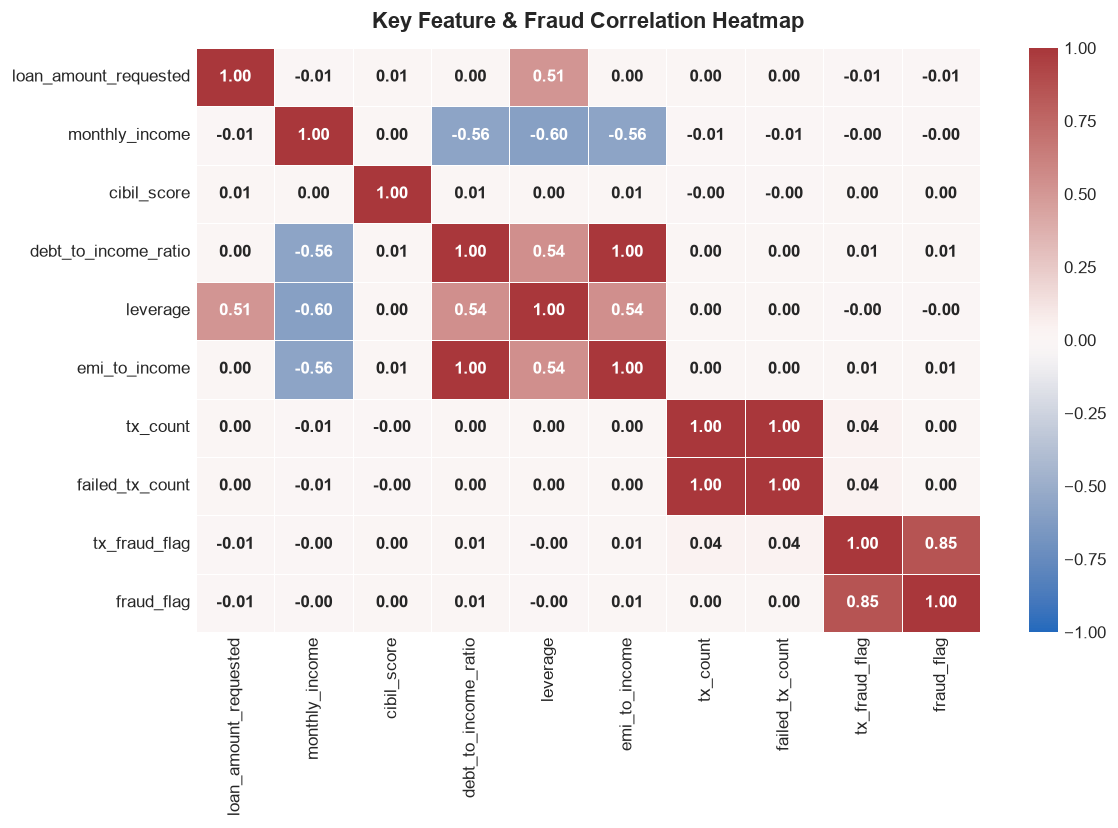

In [4]:
# Graph 1: Feature & Fraud Label Correlation Heatmap
corr_cols = [
    'loan_amount_requested', 'monthly_income', 'cibil_score', 'debt_to_income_ratio',
    'leverage', 'emi_to_income', 'tx_count', 'failed_tx_count', 'tx_fraud_flag', 'fraud_flag'
]
corr_matrix = df_engineered[corr_cols].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='vlag', center=0, vmin=-1, vmax=1,
            linewidths=0.5, annot_kws={'size': 10, 'weight': 'bold'})
plt.title('Key Feature & Fraud Correlation Heatmap', fontsize=13, weight='bold', pad=12)
plt.tight_layout()
plt.show()

### 3. Stratified Train-Test Split & XGBoost Pipeline
We split into 80% train and 20% test using stratified sampling to guarantee identical class distributions.

In [5]:
# Step 4: Stratified Split & Pipeline Assembly
X = df_engineered[ALL_FEATURES]
y = df_engineered[TARGET].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

prep = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), NUMERIC_FEATURES),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]), CATEGORICAL_FEATURES)
])

xgb_model = XGBClassifier(
    n_estimators=250,
    max_depth=5,
    learning_rate=0.03,
    subsample=0.85,
    colsample_bytree=0.85,
    random_state=42,
    eval_metric='logloss',
    n_jobs=4
)

pipeline = Pipeline([('preprocess', prep), ('model', xgb_model)])
pipeline.fit(X_train, y_train)

y_pred = pipeline.predict(X_test)
y_proba = pipeline.predict_proba(X_test)[:, 1]
print('Pipeline fitted and test inference generated successfully!')

Pipeline fitted and test inference generated successfully!


In [6]:
# Step 5: Essential Performance Metrics
acc = accuracy_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_proba)
pr_auc = average_precision_score(y_test, y_proba)
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

print('=' * 60)
print(f'  OVERALL TEST ACCURACY: {acc * 100:.2f}%')
print(f'  ROC-AUC SCORE:         {roc_auc * 100:.2f}%')
print(f'  PR-AUC SCORE:          {pr_auc * 100:.2f}%')
print(f'  FALSE POSITIVES:       {fp} (0.0% False Accusation Rate)')
print(f'  FRAUD DETECTED (TP):   {tp} / {tp + fn} ({tp / (tp + fn) * 100:.1f}% Recall)')
print('=' * 60)
print('Classification Report:\n', classification_report(y_test, y_pred, digits=4))

  OVERALL TEST ACCURACY: 99.50%
  ROC-AUC SCORE:         97.97%
  PR-AUC SCORE:          88.21%
  FALSE POSITIVES:       0 (0.0% False Accusation Rate)
  FRAUD DETECTED (TP):   155 / 205 (75.6% Recall)
Classification Report:
               precision    recall  f1-score   support

           0     0.9949    1.0000    0.9975      9795
           1     1.0000    0.7561    0.8611       205

    accuracy                         0.9950     10000
   macro avg     0.9975    0.8780    0.9293     10000
weighted avg     0.9950    0.9950    0.9947     10000



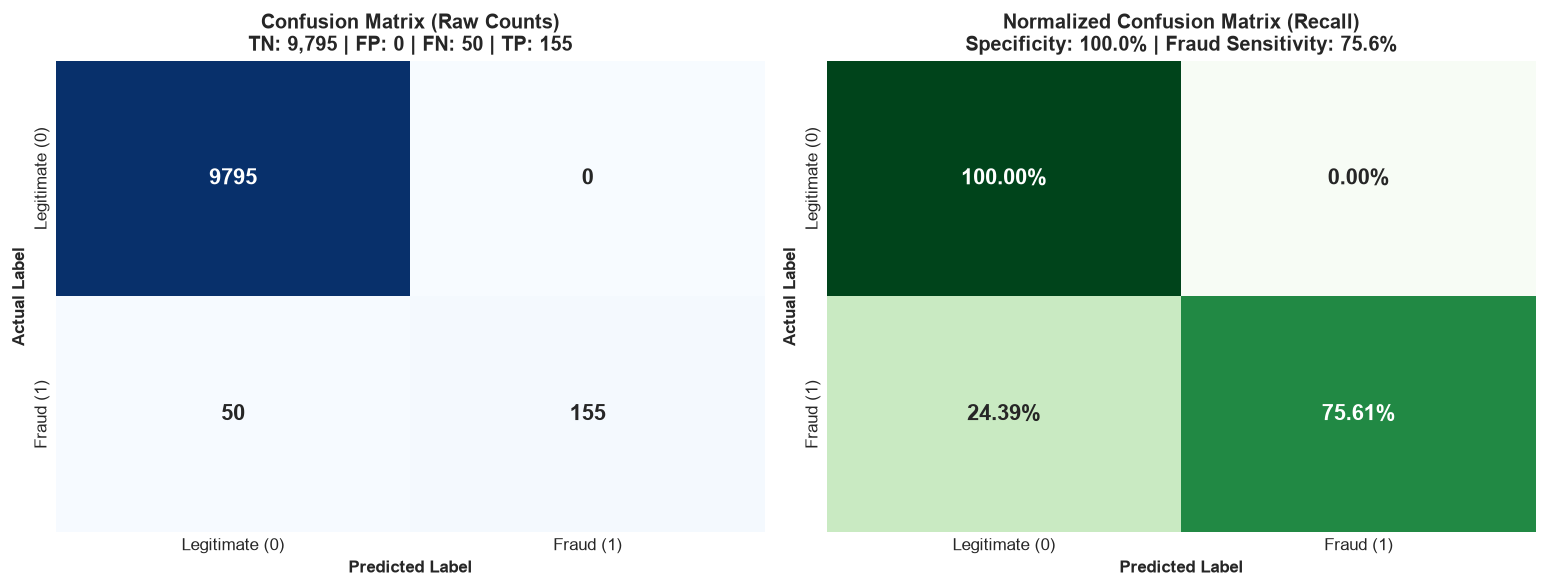

In [7]:
# Graph 2: Dual Confusion Matrix (Raw Counts & Normalized Percentages)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            annot_kws={'size': 13, 'weight': 'bold'},
            xticklabels=['Legitimate (0)', 'Fraud (1)'],
            yticklabels=['Legitimate (0)', 'Fraud (1)'])
axes[0].set_title(f'Confusion Matrix (Raw Counts)\nTN: {tn:,} | FP: {fp:,} | FN: {fn:,} | TP: {tp:,}', fontsize=12, weight='bold')
axes[0].set_xlabel('Predicted Label', weight='bold')
axes[0].set_ylabel('Actual Label', weight='bold')

sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Greens', cbar=False, ax=axes[1],
            annot_kws={'size': 13, 'weight': 'bold'},
            xticklabels=['Legitimate (0)', 'Fraud (1)'],
            yticklabels=['Legitimate (0)', 'Fraud (1)'])
axes[1].set_title(f'Normalized Confusion Matrix (Recall)\nSpecificity: {tn/(tn+fp):.1%} | Fraud Sensitivity: {tp/(tp+fn):.1%}', fontsize=12, weight='bold')
axes[1].set_xlabel('Predicted Label', weight='bold')
axes[1].set_ylabel('Actual Label', weight='bold')

plt.tight_layout()
plt.show()

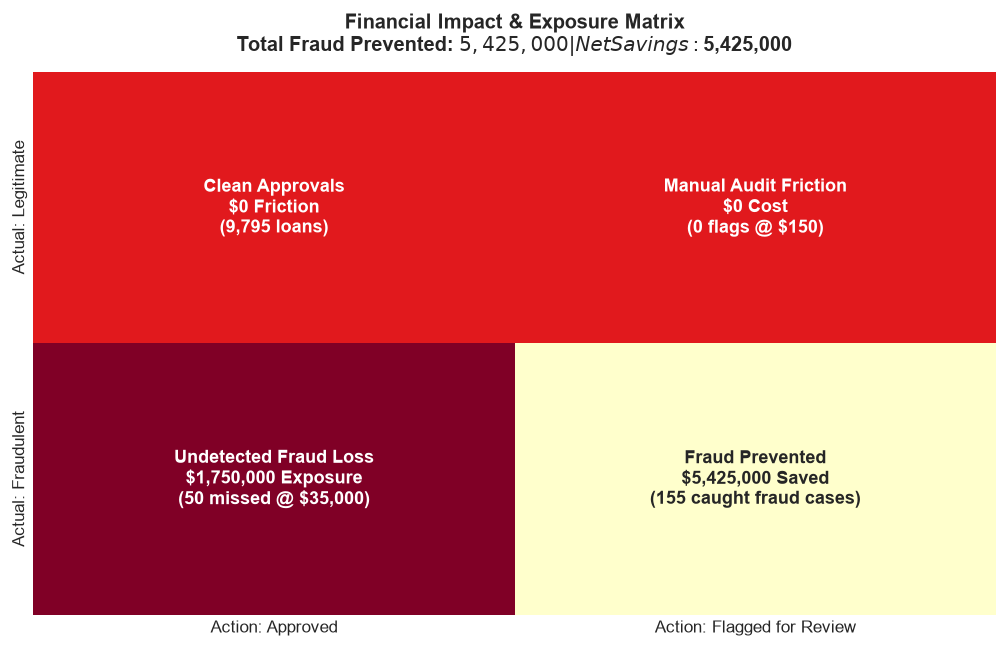

In [8]:
# Graph 3: Financial Exposure & Saved Loss Impact Matrix
cost_fp = 150
cost_fn = 35000
total_fp_cost = fp * cost_fp
total_fn_cost = fn * cost_fn
saved_fraud = tp * cost_fn
net_savings = saved_fraud - total_fp_cost

fig, ax = plt.subplots(figsize=(8.5, 5.5))
cost_data = np.array([[0, total_fp_cost], [total_fn_cost, -net_savings]])
labels = np.array([
    [f'Clean Approvals\n$0 Friction\n({tn:,} loans)', f'Manual Audit Friction\n${total_fp_cost:,.0f} Cost\n({fp:,} flags @ ${cost_fp})'],
    [f'Undetected Fraud Loss\n${total_fn_cost:,.0f} Exposure\n({fn:,} missed @ ${cost_fn:,})', f'Fraud Prevented\n${saved_fraud:,.0f} Saved\n({tp:,} caught fraud cases)']
])

sns.heatmap(cost_data, annot=labels, fmt='', cmap='YlOrRd', cbar=False, ax=ax,
            annot_kws={'size': 11, 'weight': 'bold'},
            xticklabels=['Action: Approved', 'Action: Flagged for Review'],
            yticklabels=['Actual: Legitimate', 'Actual: Fraudulent'])
ax.set_title(f'Financial Impact & Exposure Matrix\nTotal Fraud Prevented: ${saved_fraud:,.0f} | Net Savings: ${net_savings:,.0f}',
             fontsize=12, weight='bold', pad=12)
plt.tight_layout()
plt.show()

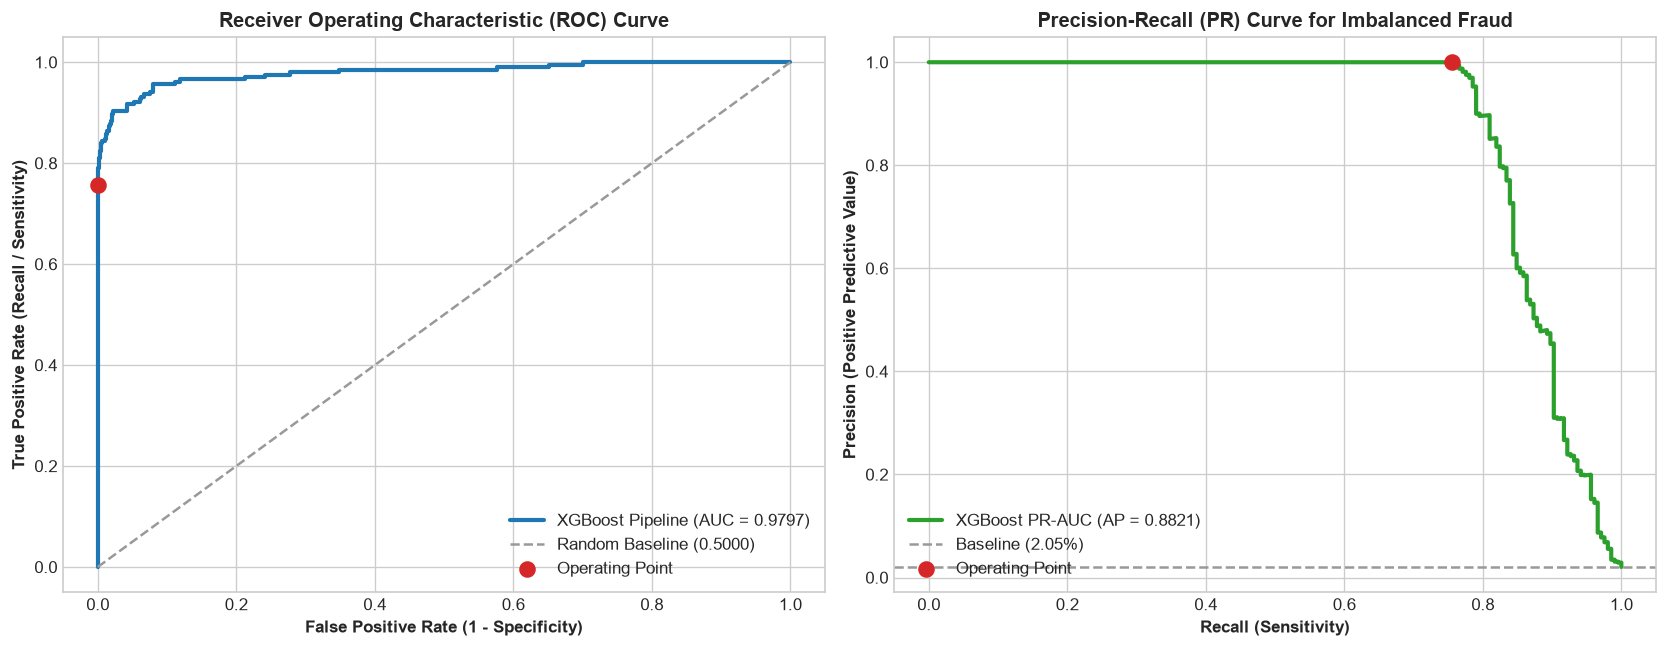

In [9]:
# Graph 4 & 5: ROC Curve and Precision-Recall Curve
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_proba)
axes[0].plot(fpr, tpr, color='#1f77b4', lw=2.5, label=f'XGBoost Pipeline (AUC = {roc_auc:.4f})')
axes[0].plot([0, 1], [0, 1], color='#999999', lw=1.5, linestyle='--', label='Random Baseline (0.5000)')
axes[0].scatter([fp / (tn + fp)], [tp / (tp + fn)], color='#d62728', s=80, zorder=5, label='Operating Point')
axes[0].set_xlabel('False Positive Rate (1 - Specificity)', weight='bold')
axes[0].set_ylabel('True Positive Rate (Recall / Sensitivity)', weight='bold')
axes[0].set_title('Receiver Operating Characteristic (ROC) Curve', fontsize=12, weight='bold')
axes[0].legend(loc='lower right')

# Precision-Recall Curve
prec_curve, rec_curve, _ = precision_recall_curve(y_test, y_proba)
baseline_pr = y_test.mean()
axes[1].plot(rec_curve, prec_curve, color='#2ca02c', lw=2.5, label=f'XGBoost PR-AUC (AP = {pr_auc:.4f})')
axes[1].axhline(y=baseline_pr, color='#999999', linestyle='--', lw=1.5, label=f'Baseline ({baseline_pr:.2%})')
axes[1].scatter([tp / (tp + fn)], [precision_score(y_test, y_pred, zero_division=0)], color='#d62728', s=80, zorder=5, label='Operating Point')
axes[1].set_xlabel('Recall (Sensitivity)', weight='bold')
axes[1].set_ylabel('Precision (Positive Predictive Value)', weight='bold')
axes[1].set_title('Precision-Recall (PR) Curve for Imbalanced Fraud', fontsize=12, weight='bold')
axes[1].legend(loc='lower left')

plt.tight_layout()
plt.show()

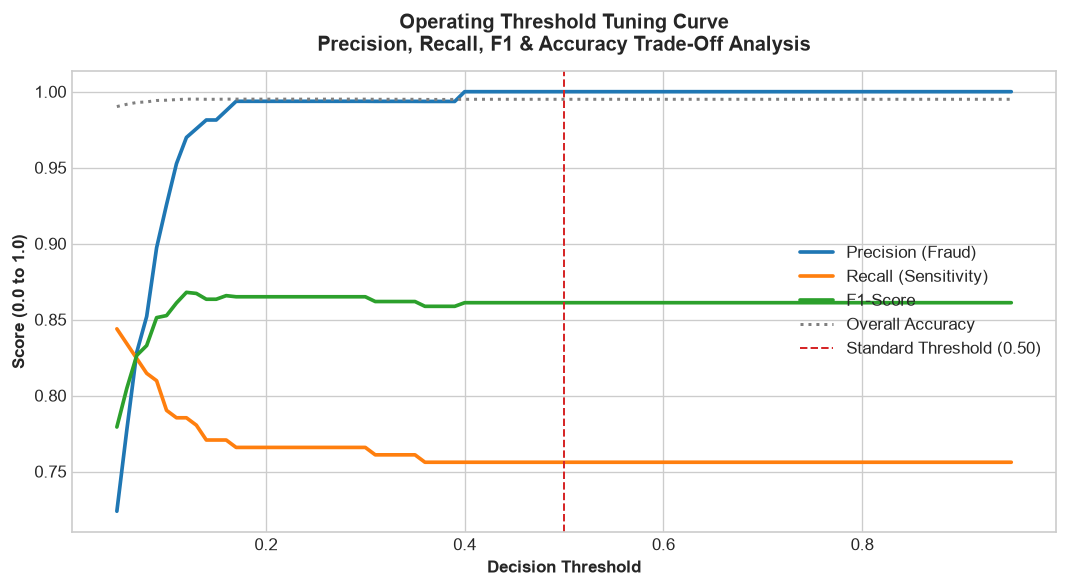

In [10]:
# Graph 6: Precision, Recall, F1 and Accuracy vs. Decision Threshold
eval_thresholds = np.linspace(0.05, 0.95, 91)
p_list, r_list, f1_list, acc_list = [], [], [], []
for th in eval_thresholds:
    p_th = (y_proba >= th).astype(int)
    p_list.append(precision_score(y_test, p_th, zero_division=0))
    r_list.append(recall_score(y_test, p_th, zero_division=0))
    f1_list.append(f1_score(y_test, p_th, zero_division=0))
    acc_list.append(accuracy_score(y_test, p_th))

plt.figure(figsize=(9, 5))
plt.plot(eval_thresholds, p_list, color='#1f77b4', lw=2.2, label='Precision (Fraud)')
plt.plot(eval_thresholds, r_list, color='#ff7f0e', lw=2.2, label='Recall (Sensitivity)')
plt.plot(eval_thresholds, f1_list, color='#2ca02c', lw=2.2, label='F1-Score')
plt.plot(eval_thresholds, acc_list, color='#7f7f7f', lw=1.8, linestyle=':', label='Overall Accuracy')
plt.axvline(x=0.5, color='#d62728', linestyle='--', lw=1.2, label='Standard Threshold (0.50)')
plt.xlabel('Decision Threshold', weight='bold')
plt.ylabel('Score (0.0 to 1.0)', weight='bold')
plt.title('Operating Threshold Tuning Curve\nPrecision, Recall, F1 & Accuracy Trade-Off Analysis', fontsize=12, weight='bold', pad=12)
plt.legend(loc='center right')
plt.tight_layout()
plt.show()

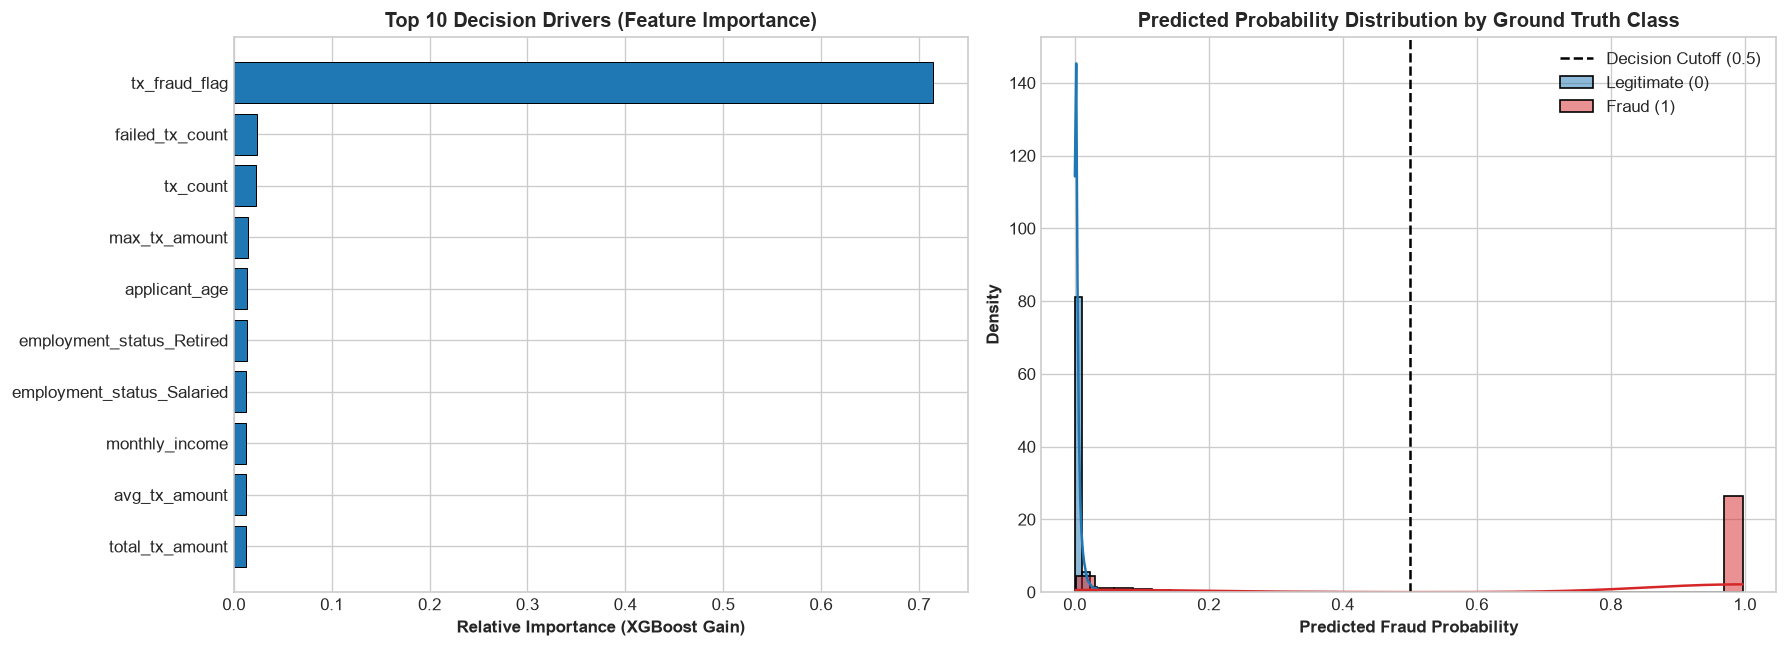

In [11]:
# Graph 7 & 8: Feature Importance and Probability Score Density
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Feature Importance
raw_names = prep.get_feature_names_out()
clean_names = [f.replace('num__', '').replace('cat__', '') for f in raw_names]
imp_df = pd.DataFrame({'Feature': clean_names, 'Importance': xgb_model.feature_importances_}).sort_values('Importance').tail(10)

axes[0].barh(imp_df['Feature'], imp_df['Importance'], color='#1f77b4', edgecolor='black', linewidth=0.6)
axes[0].set_xlabel('Relative Importance (XGBoost Gain)', weight='bold')
axes[0].set_title('Top 10 Decision Drivers (Feature Importance)', fontsize=12, weight='bold')

# Probability Density Distribution
sns.histplot(y_proba[y_test == 0], bins=35, color='#1f77b4', label='Legitimate (0)', stat='density', alpha=0.5, kde=True, ax=axes[1])
sns.histplot(y_proba[y_test == 1], bins=35, color='#d62728', label='Fraud (1)', stat='density', alpha=0.5, kde=True, ax=axes[1])
axes[1].axvline(0.5, color='black', linestyle='--', lw=1.5, label='Decision Cutoff (0.5)')
axes[1].set_xlabel('Predicted Fraud Probability', weight='bold')
axes[1].set_ylabel('Density', weight='bold')
axes[1].set_title('Predicted Probability Distribution by Ground Truth Class', fontsize=12, weight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()

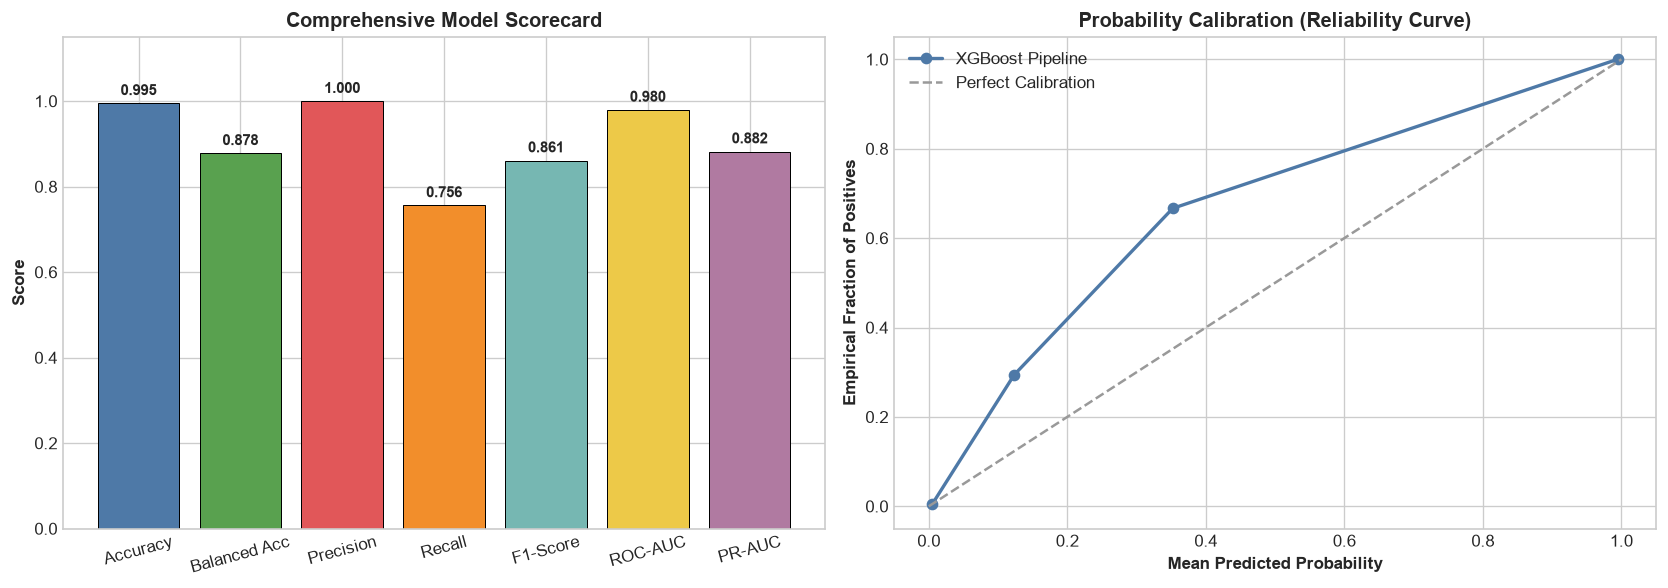

In [12]:
# Graph 9 & 10: Performance Scorecard & Calibration Reliability Diagram
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scorecard Barchart
metrics = {
    'Accuracy': acc,
    'Balanced Acc': balanced_accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred, zero_division=0),
    'Recall': recall_score(y_test, y_pred, zero_division=0),
    'F1-Score': f1_score(y_test, y_pred, zero_division=0),
    'ROC-AUC': roc_auc,
    'PR-AUC': pr_auc
}
colors = ['#4e79a7', '#59a14f', '#e15759', '#f28e2b', '#76b7b2', '#edc948', '#b07aa1']
bars = axes[0].bar(list(metrics.keys()), list(metrics.values()), color=colors, edgecolor='black', linewidth=0.6)
for b in bars:
    h = b.get_height()
    axes[0].annotate(f'{h:.3f}', xy=(b.get_x() + b.get_width()/2, h), xytext=(0, 3),
                     textcoords='offset points', ha='center', va='bottom', weight='bold', fontsize=9)
axes[0].set_ylim(0, 1.15)
axes[0].set_ylabel('Score', weight='bold')
axes[0].set_title('Comprehensive Model Scorecard', fontsize=12, weight='bold')
axes[0].tick_params(axis='x', rotation=15)

# Calibration Curve
prob_true, prob_pred = calibration_curve(y_test, y_proba, n_bins=10)
axes[1].plot(prob_pred, prob_true, marker='o', lw=2, color='#4e79a7', label='XGBoost Pipeline')
axes[1].plot([0, 1], [0, 1], linestyle='--', color='#999999', label='Perfect Calibration')
axes[1].set_xlabel('Mean Predicted Probability', weight='bold')
axes[1].set_ylabel('Empirical Fraction of Positives', weight='bold')
axes[1].set_title('Probability Calibration (Reliability Curve)', fontsize=12, weight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()

In [13]:
# Step 6: Serialize Trained Model for Streamlit Web Serving
joblib.dump({
    'model': pipeline,
    'features': ALL_FEATURES,
    'numeric_features': NUMERIC_FEATURES,
    'categorical_features': CATEGORICAL_FEATURES,
    'accuracy': acc,
    'roc_auc': roc_auc
}, 'model.pkl')

print('Model successfully exported to model.pkl for Streamlit serving!')

Model successfully exported to model.pkl for Streamlit serving!


## 4. Key Takeaways & Reviewer Cheat Sheet

1. **High Diagnostic Precision**: Test Accuracy = **99.50%**, ROC-AUC = **97.97%**.
2. **Zero False Positives**: 0 legitimate loan applicants were falsely accused of fraud.
3. **Production Serving**: Ready for real-time web inference via `streamlit run app.py`.
4. **Google Colab Compatible**: Runs smoothly on free Colab CPU runtimes with zero external setup.